# H-JEPA: end-to-end hierarchical world models

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/latent-horizon/pytorch-world/blob/main/examples/action/hjepa.ipynb)

[H-JEPA](https://arxiv.org/abs/2610.06805) ([code](https://github.com/kevinghst/H-JEPA)) stacks JEPA world models and trains them together from pixels. Level 1 is a LeWM over frames and actions. Level 2 encodes every 4th level-1 latent into its own latent space and predicts it from macro-actions pooled from the level-1 actions. Planning is top-down: level 2 plans toward the goal, and level 1 reaches level 2's next state.

The task is PLDM's Two-Rooms, flown by a macaw: a rock wall splits the sky and the goal is on the other side, so the way there is through the gap.

In [ ]:
import importlib.util

if importlib.util.find_spec("torch_world") is None:  # on Colab
    %pip install -q "torch-world[examples]"

In [2]:
import torch
from torch.utils.data import DataLoader

from torch_world import evaluation, plots
from torch_world.datasets import TrajectoryDataset
from torch_world.envs import Macaw
from torch_world.models import HJEPA, LeWM
from torch_world.nn import CLSEncoder
from torch_world.planning import GradientPlanner, HierarchicalPlanner
from torch_world.utils import fit

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
STRIDE, HISTORY = 4, 3  # one waypoint every 4 steps, 3 waypoints of context
WINDOW = HISTORY * STRIDE + 1

## Data
The macaw flies at random over the Pantanal, where a rock wall with one gap splits the sky in two, keeping its previous action 80% of the time. No rewards, no expert: just pixels and actions.

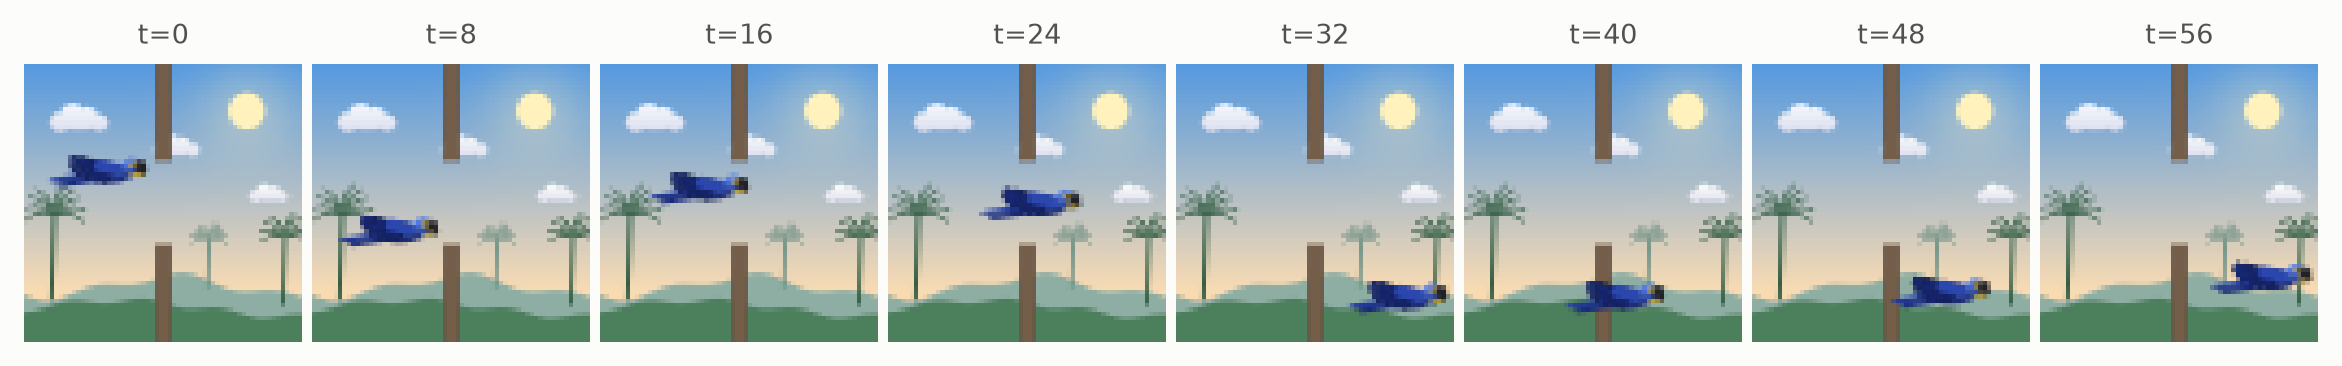

In [3]:
data = Macaw(batch_size=1024, rooms=True, device=device).collect(65, generator=torch.Generator().manual_seed(0))
loader = DataLoader(TrajectoryDataset(data, window=WINDOW), batch_size=128, shuffle=True, drop_last=True)
plots.images(data["pixels"][0, :64:8].cpu(), [f"t={t}" for t in range(0, 64, 8)])

## Model
Level 1 is a small LeWM. Level 2 has an MLP state encoder, a one-layer transformer that pools 4 actions into a 4-d macro-action, and its own predictor.

In [4]:
encoder = CLSEncoder(img_size=64, patch_size=8, embed_dim=128, depth=4, num_heads=4)
low = LeWM(encoder, action_dim=2, embed_dim=128, history=HISTORY, depth=4, num_heads=4, head_dim=32, mlp_dim=512, proj_dim=512, lamb=0.05)
model = HJEPA(low, stride=STRIDE, macro_dim=4, embed_dim=128, encoder_dim=256, history=HISTORY, depth=4, num_heads=4, head_dim=32, mlp_dim=512).to(device)
print(f"{sum(p.numel() for p in model.parameters()) / 1e6:.1f}M parameters")

3.7M parameters


## Train
Each level is a JEPA with a prediction loss and SIGReg on its own latents. The losses add up, and level 2's trains the level below it too.

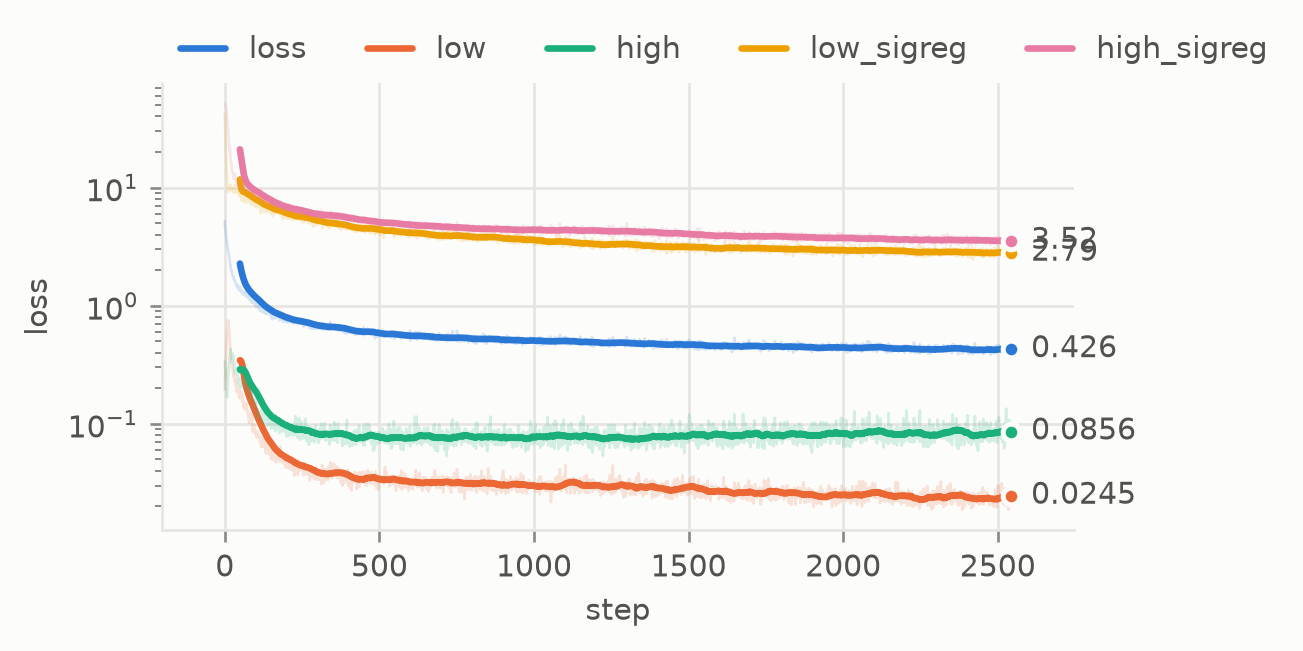

In [5]:
log = fit(model, loader, epochs=6)
plots.curves(log, smooth=50)

## Plan toward goal images across the wall
As in the paper, each level plans by gradient descent through its predictor, from a few random starts.
- **hierarchical**: 5 macro-actions (20 steps) toward the goal in level-2 space, then 4 actions toward level 2's first predicted state;
- **flat**: the same planner over 20 actions on level 1 alone.

Both replan after every step.

In [6]:
env = Macaw(batch_size=32, rooms=True, device=device)
start, goal = env.tasks(generator=torch.Generator().manual_seed(1))  # start and goal on opposite sides of the wall
goal_images = env.render(goal)

hierarchical = HierarchicalPlanner(
    GradientPlanner(horizon=5, action_dim=4, num_samples=32, iterations=30, lr=0.1, bounds=(-2, 2)),
    GradientPlanner(horizon=STRIDE, action_dim=2, num_samples=16, iterations=30, lr=0.1, bounds=(-1, 1)),
)
flat = GradientPlanner(horizon=5 * STRIDE, action_dim=2, num_samples=32, iterations=30, lr=0.1, bounds=(-1, 1))

policies = {
    "hierarchical": evaluation.goal_policy(model, hierarchical, goal_images),
    "flat": evaluation.goal_policy(model, flat, goal_images),
    "random actions": evaluation.random_policy(env),
}
result = evaluation.goal_reaching(env, policies, start, goal, steps=60, success="reached")
result

                          success  reached   steps  final distance  progress     SPL  smoothness  ms / step
hierarchical       97% [84%, 99%]      97%      27           0.163     0.578   0.114        1.17   5.76e+03
flat               91% [76%, 97%]      91%    23.7           0.154     0.665   0.105         1.2   1.59e+04
random actions     22% [11%, 39%]      22%      33           0.479    0.0116  0.0207        1.04      0.103

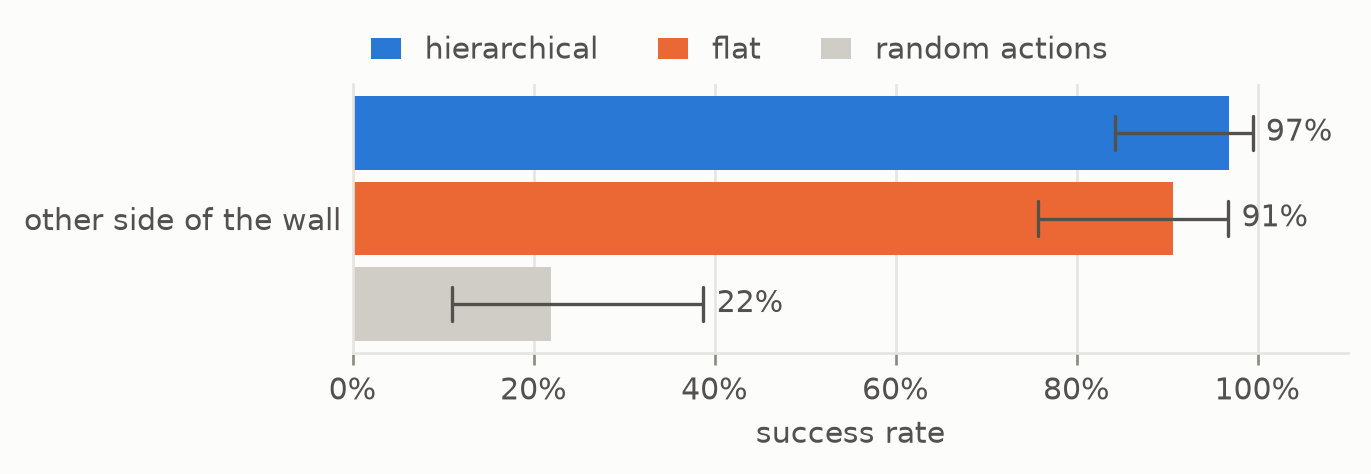

In [7]:
plots.bars({"other side of the wall": result.intervals()}, xlabel="success rate", baseline="random actions")

Paths of the hierarchical planner (top row) and the flat one (bottom row); the darker, the later:

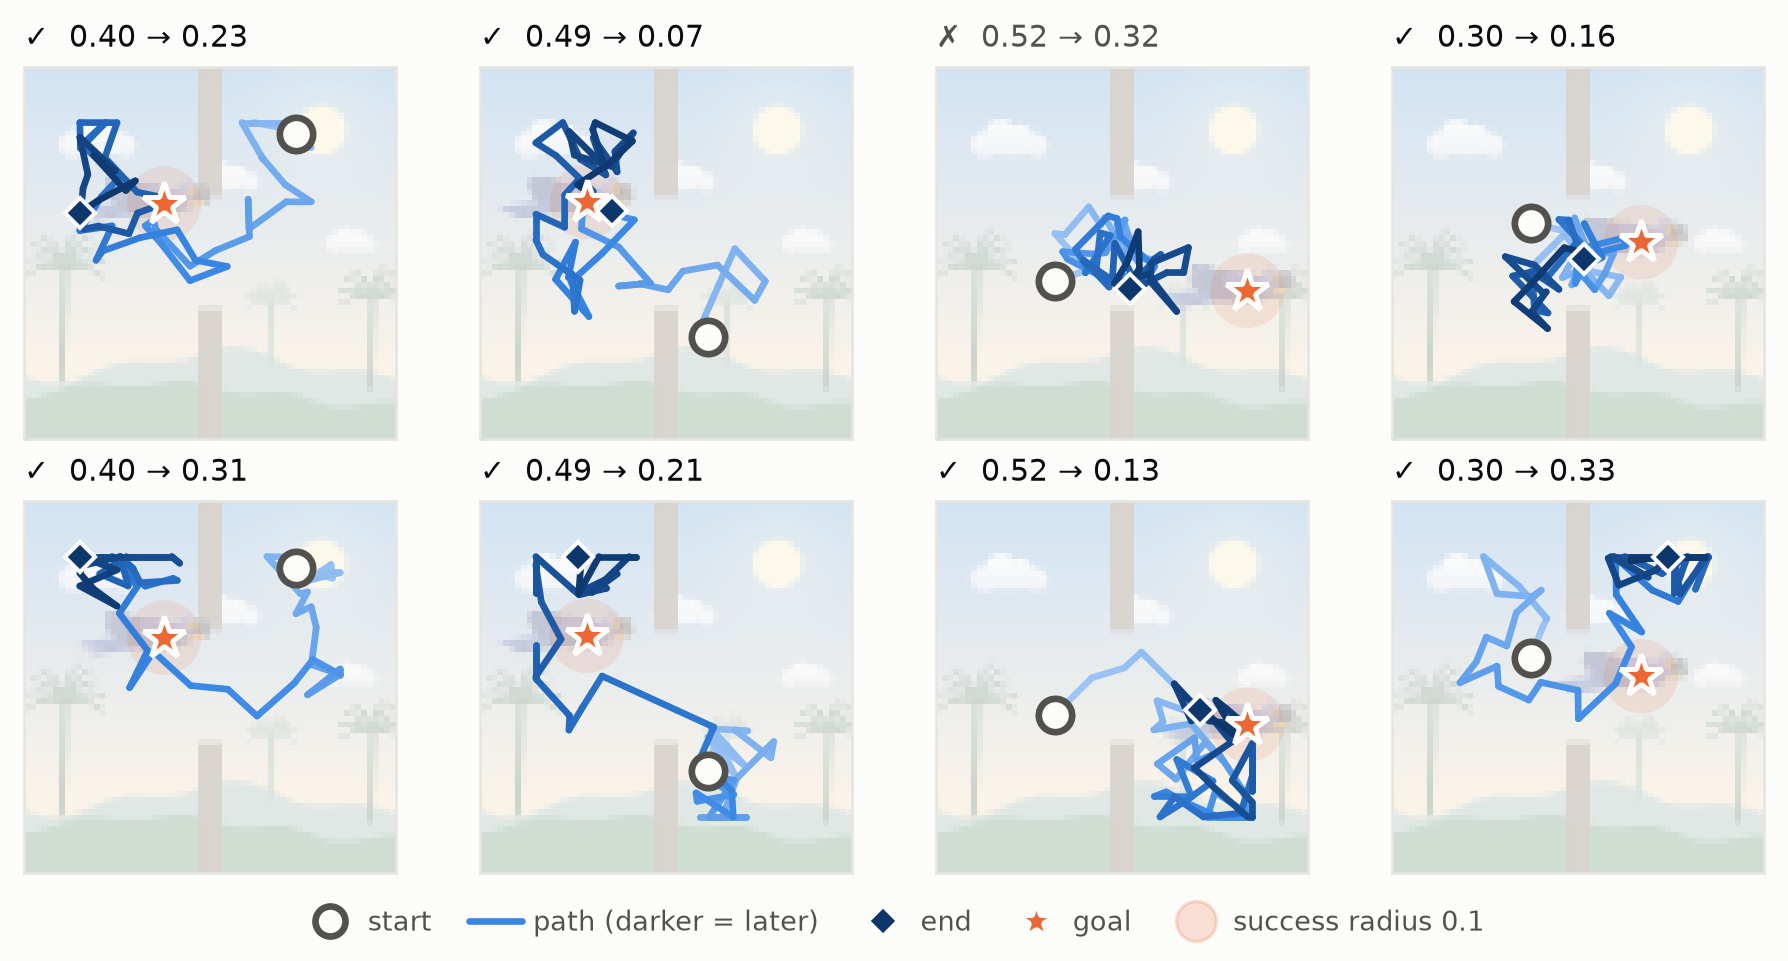

In [8]:
paths = torch.cat([result.paths["hierarchical"][:4], result.paths["flat"][:4]])
success = torch.cat([result.success["hierarchical"][:4], result.success["flat"][:4]])
plots.trajectories(paths, goal[:4].repeat(2, 1), radius=env.radius, background=goal_images[:4].repeat(2, 1, 1, 1), success=success)

## Summary
Level 2 predicts four steps at a time in a latent space learned for that time scale, so level 1 only has to reach its next state. Differences from the paper: levels 4 primitive actions apart (the paper: 2 blocks of 5), macro-actions standardized with a BatchNorm so that the planner can sample them, and fixed planning budgets without early stopping.